# Ex12 (10/12) Iris - ML + DL

Ex11(diabetes)과 같은 구조로 붓꽃 데이터에 **머신러닝 4개 모델**과 **딥러닝**을 적용합니다.

| 문제 유형 | 출력층 활성화 | 손실함수 | 평가지표 |
|---|---|---|---|
| Binary classification | sigmoid | binary_crossentropy | accuracy |
| Multi-class, single-label classification | softmax | categorical_crossentropy | accuracy |
| Regression | 없음 | mse | mae |

붓꽃은 품종이 3개이므로 **Multi-class**가 기본 문제이고, 비교를 위해 Binary(virginica인가?)와 Regression(꽃잎 너비 예측)도 함께 해봅니다.
Multi-class에서는 `categorical_crossentropy`를 쓰기 위해 정답을 **원-핫 인코딩**합니다.

In [1]:
# 구글 드라이브 마운트 (Colab에서만 동작)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, mean_absolute_error, mean_squared_error, r2_score

tf.random.set_seed(42)
np.random.seed(42)

I0000 00:00:1792959479.265610    2917 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792959480.907677    2917 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. 데이터 불러오기

In [3]:
try:
    df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Ex_0914_iris/iris.csv")
except FileNotFoundError:
    # 드라이브 파일이 없으면 scikit-learn 내장 iris 사용
    from sklearn.datasets import load_iris
    iris = load_iris(as_frame=True)
    df = iris.data.copy()
    df.columns = ['sepal_length_cm', 'sepal_width_cm', 'petal_length_cm', 'petal_width_cm']
    df['species'] = iris.target.map(dict(enumerate(iris.target_names)))

print(df.shape)
df.head()

(150, 5)


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
X = df.drop("species", axis=1)
y = df["species"]

print(y.value_counts())

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((120, 4), (30, 4), (120,), (30,))

# Classification (Machine Learning)

In [6]:
model_dt = DecisionTreeClassifier(random_state=42)
model_dt.fit(X_train, y_train)

pred_dt = model_dt.predict(X_test)
print(classification_report(y_test, pred_dt))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [7]:
model_rf = RandomForestClassifier(random_state=42)
model_rf.fit(X_train, y_train)

pred_rf = model_rf.predict(X_test)
print(classification_report(y_test, pred_rf))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



In [8]:
model_lr = LogisticRegression(max_iter=200)
model_lr.fit(X_train, y_train)

pred_lr = model_lr.predict(X_test)
print(classification_report(y_test, pred_lr))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [9]:
model_kn = KNeighborsClassifier()
model_kn.fit(X_train, y_train)

pred_kn = model_kn.predict(X_test)
print(classification_report(y_test, pred_kn))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



# DL

딥러닝은 숫자만 입력받으므로
1. 품종 문자열(setosa, versicolor, virginica)을 **LabelEncoder로 숫자(0, 1, 2)** 로 바꾸고
2. 입력값을 **StandardScaler로 정규화**합니다.

In [10]:
X = df.drop("species", axis=1).values

le = LabelEncoder()
y = le.fit_transform(df["species"])      # setosa=0, versicolor=1, virginica=2
print(le.classes_)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

[np.str_('setosa') np.str_('versicolor') np.str_('virginica')]


## DL_multi-class, single-label

### 원-핫 인코딩

`categorical_crossentropy`는 정답이 **원-핫 벡터** 형태여야 합니다.

| 품종 | 숫자 | 원-핫 |
|---|---|---|
| setosa | 0 | [1, 0, 0] |
| versicolor | 1 | [0, 1, 0] |
| virginica | 2 | [0, 0, 1] |

출력층은 클래스 개수만큼 **Dense(3, softmax)** 로 만들어, 세 품종일 확률을 각각 출력합니다. (확률의 합 = 1)

In [11]:
y_train_oh = tf.keras.utils.to_categorical(y_train, num_classes=3)
y_test_oh = tf.keras.utils.to_categorical(y_test, num_classes=3)

print("원래 정답 :", y_train[:5])
print("원-핫     :\n", y_train_oh[:5])

원래 정답 : [0 2 1 0 1]
원-핫     :
 [[1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 1. 0.]]


In [12]:
model = tf.keras.Sequential()
model.add(tf.keras.layers.Input(shape=(4,)))
model.add(tf.keras.layers.Dense(32, activation="relu"))
model.add(tf.keras.layers.Dense(16, activation="relu"))
model.add(tf.keras.layers.Dense(3, activation="softmax"))

model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 739 (2.89 KB)

 Trainable params: 739 (2.89 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
history = model.fit(X_train, y_train_oh, epochs=100, batch_size=16, validation_split=0.2, verbose=0)

print("마지막 학습 정확도 :", round(history.history['accuracy'][-1], 4))
print("마지막 검증 정확도 :", round(history.history['val_accuracy'][-1], 4))

마지막 학습 정확도 : 0.9688
마지막 검증 정확도 : 1.0


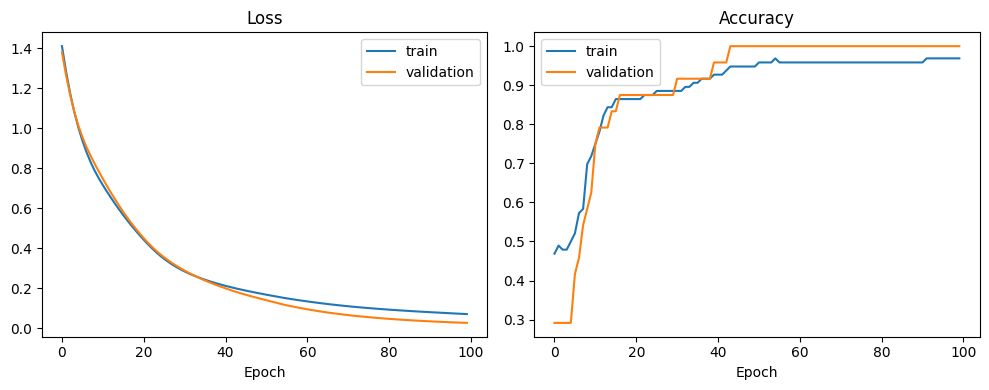

In [14]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')
plt.title('Loss'); plt.xlabel('Epoch'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='validation')
plt.title('Accuracy'); plt.xlabel('Epoch'); plt.legend()
plt.tight_layout()
plt.show()

softmax 출력은 3개 품종의 확률이므로, **가장 확률이 큰 위치(argmax)** 를 예측 품종으로 정합니다.

In [15]:
y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("확률 예시:", y_prob[0].round(3), "→ 예측:", le.classes_[y_pred[0]])

accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy =", accuracy)
print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report")
print(classification_report(y_test, y_pred, target_names=le.classes_))

확률 예시: [0.997 0.003 0.   ] → 예측: setosa

Accuracy = 0.9666666666666667

Confusion Matrix
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



## DL_Binary classification

비교를 위해 "**virginica인가 아닌가**" 두 가지로 바꿔서 이진 분류를 합니다.
출력층은 **Dense(1, sigmoid)**, 확률이 0.5 이상이면 virginica로 판단합니다. 이진 분류는 정답이 0/1 하나라서 원-핫이 필요 없습니다.

In [16]:
y_train_bin = (y_train == 2).astype(int)   # virginica=1, 나머지=0
y_test_bin = (y_test == 2).astype(int)

model_bin = tf.keras.Sequential()
model_bin.add(tf.keras.layers.Input(shape=(4,)))
model_bin.add(tf.keras.layers.Dense(32, activation="relu"))
model_bin.add(tf.keras.layers.Dense(16, activation="relu"))
model_bin.add(tf.keras.layers.Dense(1, activation="sigmoid"))

model_bin.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model_bin.fit(X_train, y_train_bin, epochs=100, batch_size=16, validation_split=0.2, verbose=0)

y_prob = model_bin.predict(X_test, verbose=0)
y_pred = (y_prob >= 0.5).astype(int).flatten()

print("Accuracy =", accuracy_score(y_test_bin, y_pred))
print("\nConfusion Matrix")
print(confusion_matrix(y_test_bin, y_pred))
print("\nClassification Report")
print(classification_report(y_test_bin, y_pred, target_names=['not virginica', 'virginica']))

Accuracy = 0.9333333333333333

Confusion Matrix
[[19  1]
 [ 1  9]]

Classification Report
               precision    recall  f1-score   support

not virginica       0.95      0.95      0.95        20
    virginica       0.90      0.90      0.90        10

     accuracy                           0.93        30
    macro avg       0.93      0.93      0.93        30
 weighted avg       0.93      0.93      0.93        30



## DL_Regression

회귀는 **숫자 값을 예측**하는 문제입니다. 나머지 3개 변수로 **꽃잎 너비(마지막 열)** 를 예측합니다.
출력층은 활성화 함수 없이 **Dense(1)**, 손실은 **mse**, 평가는 **mae**(평균 몇 cm 틀렸는지)로 합니다.
회귀 결과는 연속된 값이라 accuracy나 confusion matrix로 평가할 수 없습니다.

In [17]:
feature_names = df.drop("species", axis=1).columns
target_name = feature_names[-1]
print("예측 대상:", target_name)

X_reg = df[feature_names[:-1]].values
y_reg = df[target_name].values

Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

scaler_r = StandardScaler()
Xr_train = scaler_r.fit_transform(Xr_train)
Xr_test = scaler_r.transform(Xr_test)

model_reg = tf.keras.Sequential()
model_reg.add(tf.keras.layers.Input(shape=(3,)))
model_reg.add(tf.keras.layers.Dense(32, activation="relu"))
model_reg.add(tf.keras.layers.Dense(16, activation="relu"))
model_reg.add(tf.keras.layers.Dense(1))

model_reg.compile(optimizer="adam", loss="mse", metrics=["mae"])
model_reg.fit(Xr_train, yr_train, epochs=200, batch_size=16, validation_split=0.2, verbose=0)

yr_pred = model_reg.predict(Xr_test, verbose=0).flatten()

print(f"MAE  = {mean_absolute_error(yr_test, yr_pred):.3f} cm")
print(f"RMSE = {np.sqrt(mean_squared_error(yr_test, yr_pred)):.3f} cm")
print(f"R2   = {r2_score(yr_test, yr_pred):.3f}")

예측 대상: petal_width_cm


MAE  = 0.152 cm
RMSE = 0.212 cm
R2   = 0.929


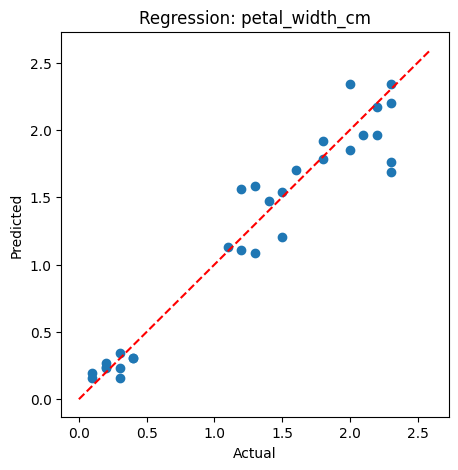

In [18]:
plt.figure(figsize=(5, 5))
plt.scatter(yr_test, yr_pred)
plt.plot([0, 2.6], [0, 2.6], 'r--')
plt.xlabel('Actual'); plt.ylabel('Predicted')
plt.title(f'Regression: {target_name}')
plt.show()

# 결과 정리

- **ML**: 4개 모델 모두 정확도가 높습니다. 붓꽃은 꽃잎 길이/너비만으로도 품종이 잘 구분되는 쉬운 데이터입니다.
- **DL Multi-class**: 정답을 원-핫으로 바꾸고 softmax(3) + categorical_crossentropy로 학습했습니다. 예측은 argmax로 가장 확률이 큰 품종을 고릅니다.
- **DL Binary**: 출력이 하나(sigmoid)이고 0.5 기준으로 판단합니다. 원-핫이 필요 없습니다.
- **DL Regression**: 출력층에 활성화 함수가 없고, mse로 학습해 mae로 평가합니다.
- 주의: Multi-class에서 출력층을 `Dense(1, softmax)`로 만들면 출력이 항상 1이 되어 학습이 되지 않습니다. 출력 노드 수 = 클래스 수여야 합니다.